# P6 - Operasi Morfologi dan Komponen Terhubung

In [1]:
from google.colab import drive
import os
import sys

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Arahkan direktori kerja aktif ke dalam folder 'notebook' Anda di Drive
os.chdir('/content/drive/MyDrive/Computer Vision/simuteh-2330511084/notebook')

# 3. Masukkan folder 'src' ke dalam sys.path secara mutlak (absolute path)
src_path = '/content/drive/MyDrive/Computer Vision/simuteh-2330511084/src'
if src_path not in sys.path:
    sys.path.append(src_path)

print("Berhasil! Direktori saat ini:", os.getcwd())

Mounted at /content/drive
Berhasil! Direktori saat ini: /content/drive/MyDrive/Computer Vision/simuteh-2330511084/notebook


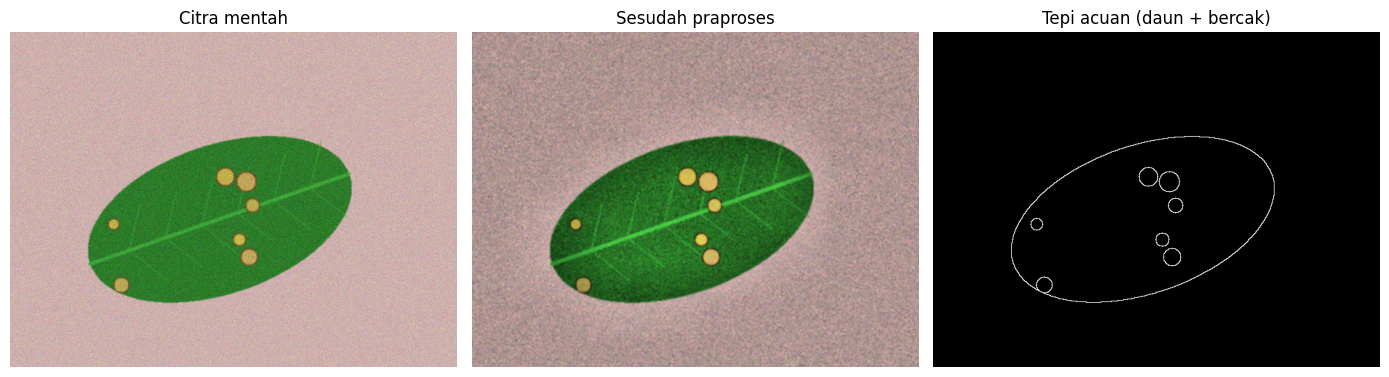

In [2]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

In [3]:
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

## Bagian 3. Operasi Morfologi pada Citra Biner

### Langkah 3.1 Lembar hitung manual (kerjakan di kertas)
SE persegi 3x3, piksel di luar citra = 0.
```
B = [[0,0,0,0,0,0,0,0,0],
     [0,1,1,1,0,0,0,0,0],
     [0,1,0,1,0,0,0,1,0],
     [0,1,1,1,0,0,0,0,0],
     [0,0,0,0,1,0,0,0,0],
     [0,0,0,0,0,0,0,0,0],
     [0,0,0,0,0,0,0,0,0],
     [0,1,1,1,1,1,1,0,0],
     [0,0,0,0,0,0,0,0,0]]
```
a) Jumlah komponen terhubung konektivitas 4 dan 8.  
b) Hasil erosi dan hasil opening B.  
c) Hasil closing B (perhatikan lubang bercak dan celah piksel diagonal-garis).  
d) Hasil closing lalu opening.

**Catatan hasil hitung manual saya:**
- a) Konektivitas 4 → **4 komponen** (bercak berlubang, titik derau, piksel diagonal, garis). Konektivitas 8 → **3 komponen**, karena piksel (baris 5, kolom 5) menyentuh sudut bercak secara diagonal sehingga ikut menyatu dengannya.
- b) **Erosi** → semua nol: tidak ada daerah 3×3 penuh (bercak hanya cincin 1 piksel, garis hanya 1 piksel tebal). **Opening** (erosi lalu dilasi) → semua nol, karena tidak ada yang tersisa untuk dikembalikan.
- c) **Closing**: lubang bercak tertutup (menjadi blok 3×3 penuh) dan celah antara piksel diagonal dan garis terisi di kolom 5 baris 6–7, sehingga piksel diagonal tersambung ke garis. Titik derau (baris 3, kolom 8) tetap.
- d) **Closing lalu opening**: hanya blok 3×3 bercak yang tersisa. Titik derau, piksel diagonal, jembatan, dan garis terhapus oleh opening.


In [4]:
# Cek hitungan - jalankan SETELAH menghitung manual
B = np.array([[0,0,0,0,0,0,0,0,0],
              [0,1,1,1,0,0,0,0,0],
              [0,1,0,1,0,0,0,1,0],
              [0,1,1,1,0,0,0,0,0],
              [0,0,0,0,1,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,1,1,1,1,1,1,0,0],
              [0,0,0,0,0,0,0,0,0]], np.uint8)
se3 = np.ones((3, 3), np.uint8)
for konek in (4, 8):
    print("konektivitas", konek, ":", cv2.connectedComponents(B, connectivity=konek)[0] - 1, "komponen")
er  = cv2.erode(B, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
op  = cv2.morphologyEx(B, cv2.MORPH_OPEN,  se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
cl  = cv2.morphologyEx(B, cv2.MORPH_CLOSE, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
clo = cv2.morphologyEx(cl, cv2.MORPH_OPEN, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
for nm, m in [("erosi", er), ("opening", op), ("closing", cl), ("closing lalu opening", clo)]:
    print("\n" + nm); print(m)

konektivitas 4 : 4 komponen
konektivitas 8 : 3 komponen

erosi
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

opening
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

closing
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 1 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]]

closing lalu opening
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]


### Langkah 3.2 Citra biner awal (Kode 3.1)

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.996                   174               7           0.661
1  teh_021.png          0.999                   222               2           0.106
2  teh_011.png          0.998                   221               0               -


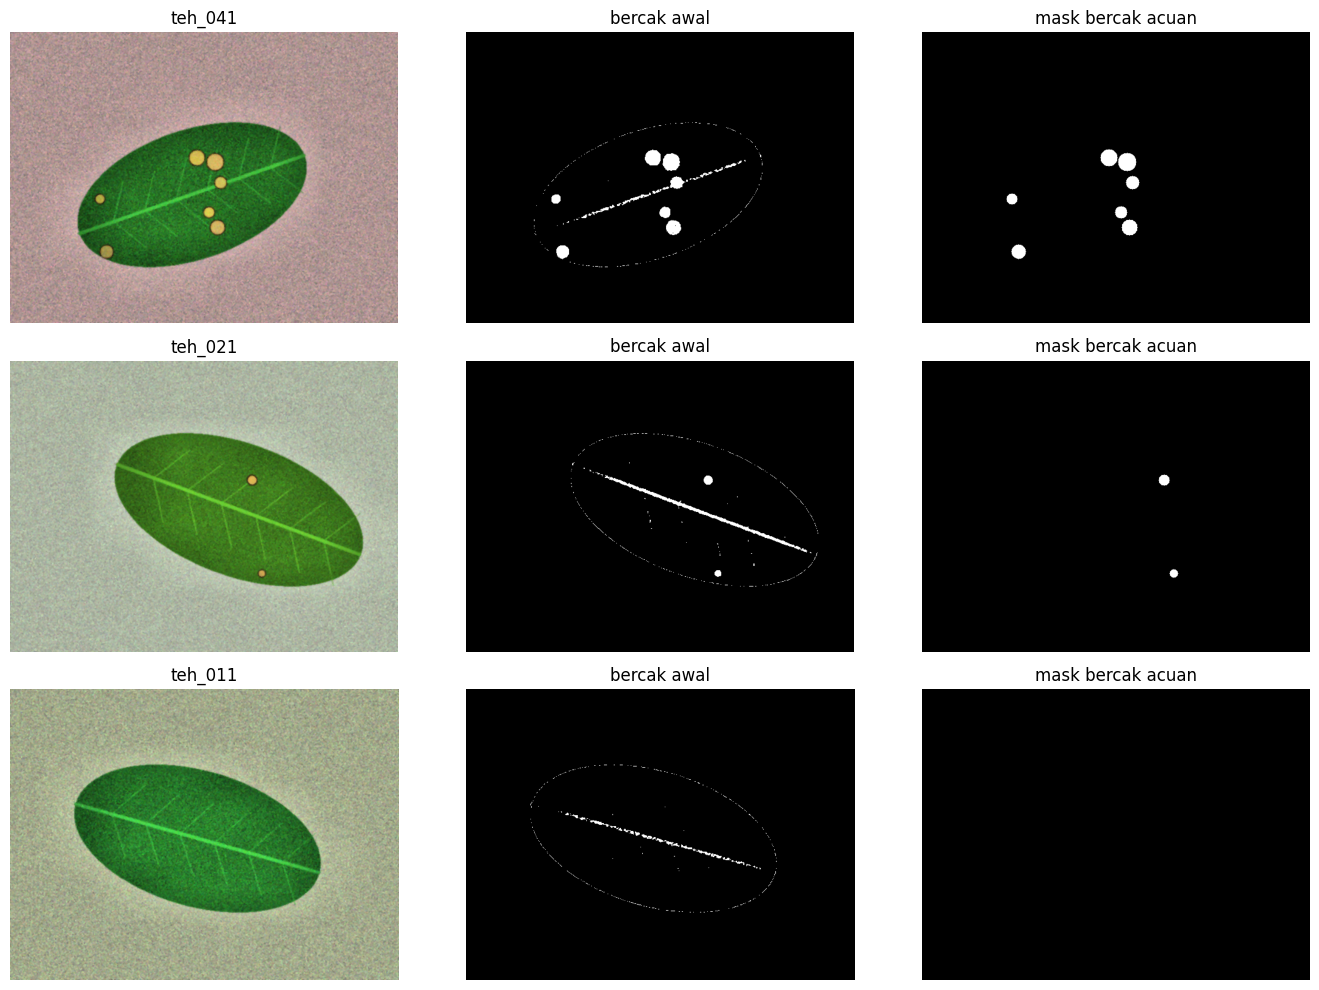

In [5]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:     # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))

### Langkah 3.3 Enam operasi (Kode 3.2)

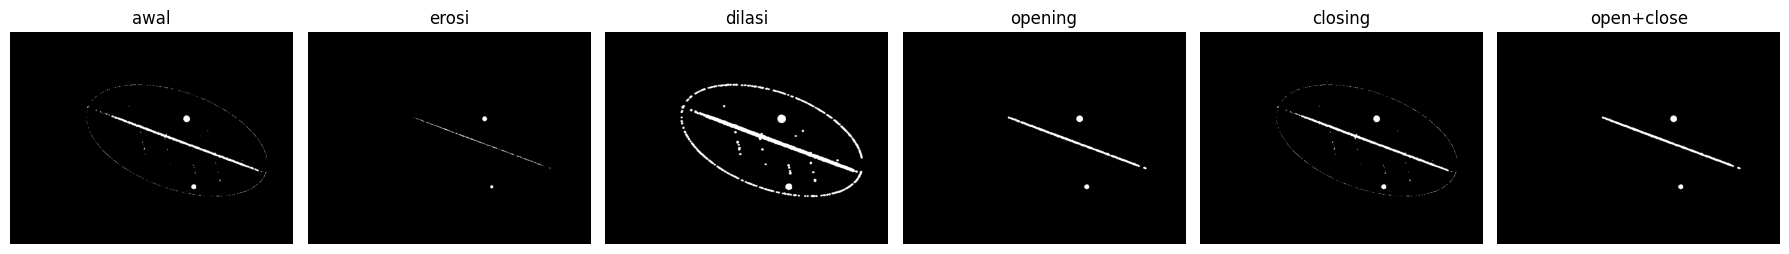

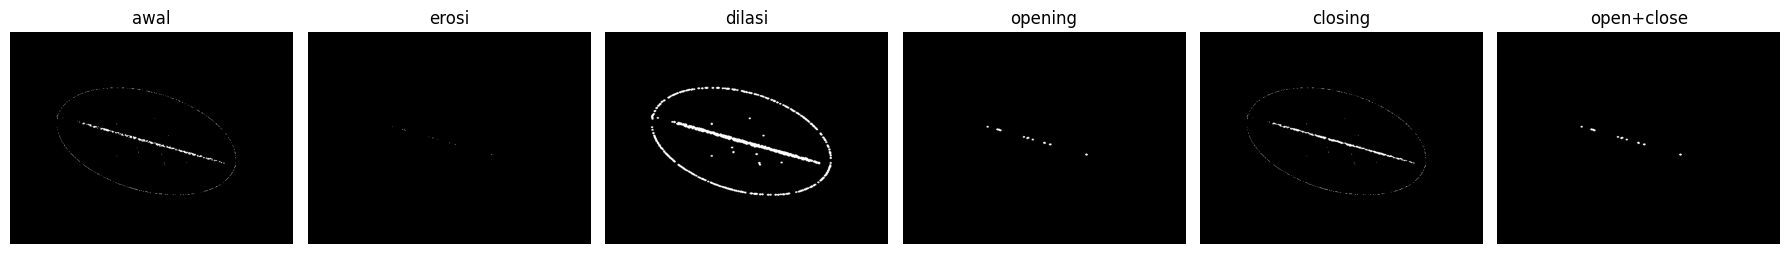

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       222    2511  0.106
1   teh_021.png       erosi        22     514   0.17
2   teh_021.png      dilasi        58    8043   0.05
3   teh_021.png     opening         4    1883  0.136
4   teh_021.png     closing       213    2590  0.103
5   teh_021.png  open+close         4    1905  0.135
6   teh_011.png        awal       221    1299      -
7   teh_011.png       erosi         9      18      -
8   teh_011.png      dilasi        50    6332      -
9   teh_011.png     opening         8     197      -
10  teh_011.png     closing       192    1494      -
11  teh_011.png  open+close         9     198      -


In [6]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3)); plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

### Langkah 3.4 Eksperimen k, bentuk, dan ukuran SE (Kode 3.3)
(Menjalankan 60 citra x 27 kombinasi; perlu beberapa menit.)

In [7]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.58   0.14        15.95  42.05  21.75
          5       0.62   0.23         4.00   4.80   4.90
          7       0.71   0.32         1.70   2.40   2.60
  persegi 3       0.59   0.18         5.55   7.25   7.75
          5       0.67   0.29         3.45   3.20   3.25
          7       0.71   0.37         0.60   0.90   0.05
  silang  3       0.58   0.14        15.95  42.05  21.75
          5       0.62   0.22         6.95   7.60   7.05
          7       0.71   0.33         3.45   3.55   4.85
4 elips   3       0.63   0.23        12.80  21.75  14.65
          5       0.68   0.35         2.75   3.20   3.10
          7       0.70   0.39         0.35   0.85   0.25
  persegi 3       0.64   0.27         7.50   7.10   7.05
          5       0.70   0.40         0.60   1.60   2.00
          7       0.67   0.32  

**Tabel 9.** Ringkasan eksperimen SE untuk k = 4 (disalin dari keluaran Kode 3.3)

| Bentuk SE | Ukuran | IoU berat | IoU ringan | Galat jumlah berat | Galat jumlah ringan | Galat jumlah sehat |
|---|---|---|---|---|---|---|
| persegi | 3 | 0,64 | 0,27 | 7,50 | 7,10 | 7,05 |
| persegi | 5 | 0,70 | 0,40 | 0,60 | 1,60 | 2,00 |
| persegi | 7 | 0,67 | 0,32 | 0,60 | 1,00 | 0,00 |
| elips | 3 | 0,63 | 0,23 | 12,80 | 21,75 | 14,65 |
| elips | 5 | 0,68 | 0,35 | 2,75 | 3,20 | 3,10 |
| elips | 7 | 0,70 | 0,39 | 0,35 | 0,85 | 0,25 |
| silang | 3 | 0,63 | 0,23 | 12,80 | 21,75 | 14,65 |
| silang | 5 | 0,68 | 0,34 | 5,65 | 4,80 | 5,40 |
| silang | 7 | 0,70 | 0,39 | 0,35 | 1,30 | 0,35 |

Catatan: untuk k = 6 (keluaran yang sama) elips 5 memberi IoU 0,65/0,41 dengan galat jumlah 0,55/0,55/0,05 (berat/ringan/sehat), sehingga k = 6 dengan elips 5 dipilih sebagai kombinasi terbaik secara keseluruhan (lihat P3.4).


### Langkah 3.5 Gradien morfologi vs Canny  `# DARI PETUNJUK` (Kode 3.4)

In [8]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))     # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
      .groupby("kondisi").mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.898     0.703
gelap                          0.976     0.698
kontras_rendah                 0.141     0.881
normal                         0.988     0.694
terang                         0.915     0.702


In [9]:
# Pendukung P3.5: apakah mask daun awal (Otsu kanal saturasi) gagal pada kondisi tertentu?
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    baris.append([d.kondisi_cahaya, iou(mask_daun_awal(pra_), md), iou(mask_daun_awal(img), md)])
print(pd.DataFrame(baris, columns=["kondisi", "IoU mask daun (praproses)", "IoU mask daun (mentah)"])
      .groupby("kondisi").mean().round(3))

                IoU mask daun (praproses)  IoU mask daun (mentah)
kondisi                                                          
bayangan                            0.994                   0.941
gelap                               0.996                   0.982
kontras_rendah                      0.825                   0.532
normal                              0.997                   0.990
terang                              0.995                   0.956


### Langkah 3.6 KERJAKAN SENDIRI
Tampilkan elemen SE persegi, elips, dan silang berukuran 3, 5, 7 (`cv2.getStructuringElement`) dalam satu panel (grid 3x3 dengan `plt.imshow`). Panel ini dipakai menjelaskan hasil eksperimen Kode 3.3.

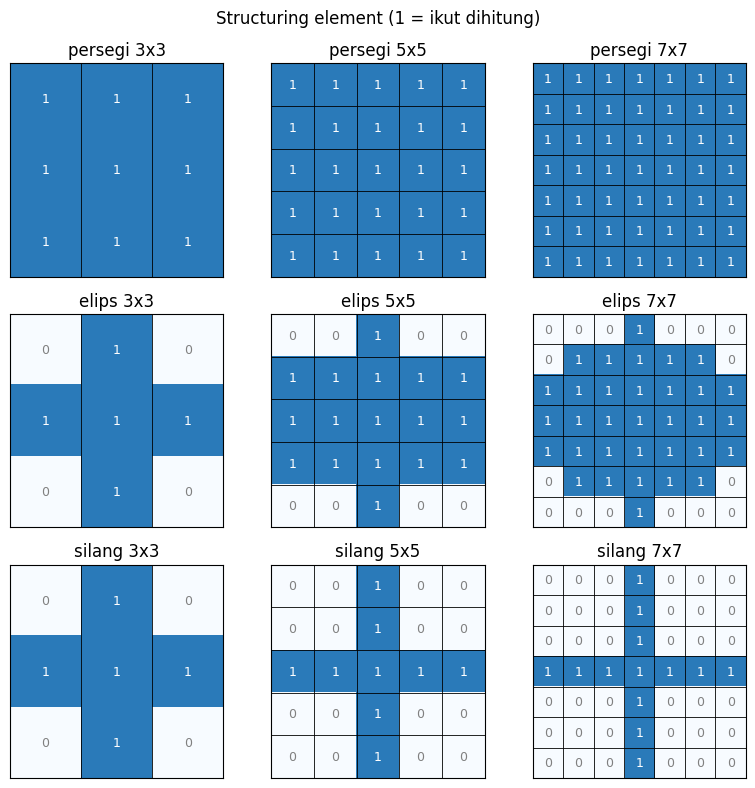

elips 3x3 == silang 3x3 ? True


In [10]:
# Langkah 3.6: panel SE persegi, elips, silang berukuran 3, 5, 7
bentuk_se = [("persegi", cv2.MORPH_RECT), ("elips", cv2.MORPH_ELLIPSE), ("silang", cv2.MORPH_CROSS)]
fig, axs = plt.subplots(3, 3, figsize=(8, 8))
for i, (nb_, kb_) in enumerate(bentuk_se):
    for j, uk in enumerate([3, 5, 7]):
        se = cv2.getStructuringElement(kb_, (uk, uk))
        ax = axs[i, j]
        ax.imshow(se, cmap="Blues", vmin=0, vmax=1.4)
        for (r, c), v in np.ndenumerate(se):
            ax.text(c, r, int(v), ha="center", va="center", fontsize=9, color="white" if v else "gray")
        ax.set_xticks(np.arange(-.5, uk, 1), minor=True); ax.set_yticks(np.arange(-.5, uk, 1), minor=True)
        ax.grid(which="minor", color="black", linewidth=0.6)
        ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
        ax.set_title(f"{nb_} {uk}x{uk}")
plt.suptitle("Structuring element (1 = ikut dihitung)")
plt.tight_layout()
plt.savefig("../hasil/p6_panel_se.png", dpi=150, bbox_inches="tight")
plt.show()
# bukti untuk P3.4: elips 3x3 identik dengan silang 3x3
print("elips 3x3 == silang 3x3 ?",
      np.array_equal(cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)),
                     cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))))

### Pertanyaan Analisis Bagian 3
- **P3.1** Mengapa erosi saja dan opening saja menghapus bercak berlubang? Apa yang terjadi pada celah piksel diagonal-garis saat closing, dan mengapa berisiko bagi penghitungan bercak?
- **P3.2** Konektivitas 4 atau 8 untuk menghitung bercak? Contoh dari lembar hitung dan alasan bentuk bercak nyata.
- **P3.3** Mengapa opening membuang titik derau dan tepi daun, sedangkan closing saja hampir tidak mengurangi jumlah komponen? Mengapa potongan tulang daun pada daun sehat masih tersisa setelah opening?
- **P3.4** Kombinasi k, bentuk, ukuran SE pilihan Anda (berdasarkan Tabel 9)? Trade-off bercak ringan vs bercak palsu daun sehat. Mengapa elips 3x3 identik dengan silang 3x3?
- **P3.5** Mengapa gradien morfologi mask daun lebih baik dari Canny pada kontras rendah? Kapan Canny tetap diperlukan?

### Draf jawaban Bagian 3 (rujuk gambar dan tabel milik Anda)

**P3.1.** Bercak pada lembar hitung hanya berupa cincin setebal 1 piksel dengan lubang di tengah, dan garis juga setebal 1 piksel. Erosi 3×3 menghapus semua piksel yang tidak punya seluruh 8 tetangga bernilai 1, sehingga cincin tipis habis. Opening = erosi lalu dilasi: karena hasil erosi kosong, dilasi tidak punya apa pun untuk dikembalikan, jadi opening juga menghapus bercak berlubang. Pada closing, lubang bercak tertutup, dan celah antara piksel diagonal dan garis (dua baris kosong di kolom 5) ikut terisi sehingga piksel diagonal tersambung ke garis dan ke bercak. Risikonya bagi SIMUTEH: bercak benar dapat menyatu dengan derau atau potongan tulang daun, sehingga jumlah komponen berkurang, luas membesar, dan bentuk (kebulatan, rasio aspek) menjadi salah untuk penyaringan.

**P3.2.** Konektivitas 8 lebih tepat. Pada lembar hitung, konektivitas 4 menghasilkan 4 komponen karena piksel diagonal dianggap terpisah, sedangkan konektivitas 8 menghasilkan 3. Pada piksel nyata, tepi bercak membulat sehingga mengandung langkah diagonal; konektivitas 4 dapat memecah satu bercak menjadi beberapa komponen. Pada teh_041 hasil bersihnya sama (10 komponen pada konektivitas 4 dan 8, keluaran Kode 4.1) karena opening dan closing sudah merapikan tepi. Kelemahan konektivitas 8: dua bercak yang hanya bersentuhan di sudut dihitung satu.

**P3.3.** Dari keluaran Kode 3.2 pada teh_021: komponen 222 → 4 setelah opening, tetapi hanya 222 → 213 setelah closing. Opening membuang objek yang lebih kecil dari SE elips 5×5, yaitu titik derau dan tepi daun yang tipis (1–2 piksel). Closing hanya menutup lubang dan celah; objek kecil tetap ada (bahkan dapat tersambung), sehingga jumlah komponen hampir tidak turun. Pada daun sehat teh_011 opening menurunkan komponen 221 → 8 (piksel 1299 → 197): bagian tulang daun yang cukup tebal untuk memuat SE 5×5 tetap bertahan (tampak sebagai titik atau garis putus pada Gambar 4).

**P3.4.** Pilihan: **k = 6, SE elips 5×5** (opening dan closing). Dasar: pada k = 6 elips 5 galat jumlah 0,55 (berat), 0,55 (ringan), 0,05 (sehat) dengan IoU 0,65 dan 0,41. Pada k = 4 yang terbaik adalah elips 7 (galat 0,35/0,85/0,25; IoU 0,70/0,39), tetapi SE 7×7 lebih berisiko membuang bercak ringan yang kecil. Trade-off: SE yang makin besar atau k yang makin tinggi menurunkan bercak palsu pada daun sehat tetapi juga melenyapkan bercak ringan yang kecil dan redup (IoU ringan paling tinggi hanya 0,43). Elips 3×3 identik dengan silang 3×3 karena kedua elemen berisi pola yang sama [[0,1,0],[1,1,1],[0,1,0]] (lihat panel Langkah 3.6 dan keluaran `np.array_equal`); itu sebabnya barisnya sama persis pada Tabel 9.

**P3.5.** Jawab dengan keluaran Kode 3.4 dan sel pendukung P3.5. Pada keluaran Anda gradien morfologi mengungguli Canny pada kondisi normal (0,988 vs 0,694), gelap (0,976 vs 0,698), terang (0,915 vs 0,702), dan bayangan (0,898 vs 0,703). Namun pada **kontras_rendah** gradien morfologi hanya 0,141, sedangkan Canny 0,881. Jadi pada data Anda dugaan "lebih baik terutama pada kontras rendah" tidak terbukti; jelaskan hal ini secara jujur. Penyebab yang perlu Anda buktikan dengan sel pendukung: gradien morfologi hanya sebaik mask daunnya; jika Otsu pada kanal saturasi gagal memisahkan daun dari nampan pada kontras rendah (IoU mask daun rendah), tepinya ikut salah. Canny bekerja langsung pada gradien intensitas sehingga tetap bisa menemukan tepi yang lemah. Canny tetap diperlukan bila mask belum dapat dipercaya (kontras rendah) atau untuk tepi internal yang tidak diwakili mask, misalnya tepi bercak.


## Bagian 4. Komponen Terhubung dan Pengukuran Bercak

### Langkah 4.1 Lembar hitung manual (kerjakan di kertas)
Pakai hasil soal 3.1 butir d) dan garis pada baris ke-8 citra B. Keliling = jumlah sisi piksel yang berbatasan dengan latar. 1 piksel = 0,4375 mm.

a) Luas (piksel dan mm²), keliling, kebulatan 4·pi·luas/keliling², dan rasio aspek bercak 3x3.  
b) Hal yang sama untuk garis 1x6 piksel.  
c) Aturan sederhana berdasarkan kebulatan dan rasio aspek untuk membedakan bercak dari potongan tulang daun.

**Catatan hasil hitung manual saya:**
- a) Bercak 3×3 (hasil closing lalu opening): luas **9 px = 1,72 mm²** (9 × 0,4375² = 1,7227), keliling **12**, kebulatan 4π·9/12² = **0,785**, rasio aspek **1**.
- b) Garis 1×6: luas **6 px = 1,15 mm²**, keliling **14**, kebulatan 4π·6/14² = **0,385**, rasio aspek **6**.
- c) Aturan: objek dianggap **bercak** bila kebulatan ≥ 0,5 dan rasio aspek ≤ 1,8; di luar itu dicurigai potongan tulang daun. Bercak 3×3 lolos, garis 1×6 tidak.


### Langkah 4.2 Label dan ukur (Kode 4.1)

konektivitas 4: 10 komponen
konektivitas 8: 10 komponen
   label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0      1     1198    229.30        183.1       0.45         1.99  324  210
1      2       22      4.21         15.7       1.13         1.25  441  218
2      3      342     65.46         72.8       0.81         1.14  347  248
3      4      190     36.37         48.4       1.02         1.00  147  274
4      5       41      7.85         24.5       0.86         2.17  278  274
5      6       27      5.17         17.7       1.09         1.50  231  291
6      7      267     51.11         58.9       0.97         1.06  327  297
7      8       17      3.25         13.7       1.15         1.25  196  304
8      9      463     88.62         82.4       0.86         1.04  341  321
9     10      370     70.82         69.7       0.96         1.05  158  362


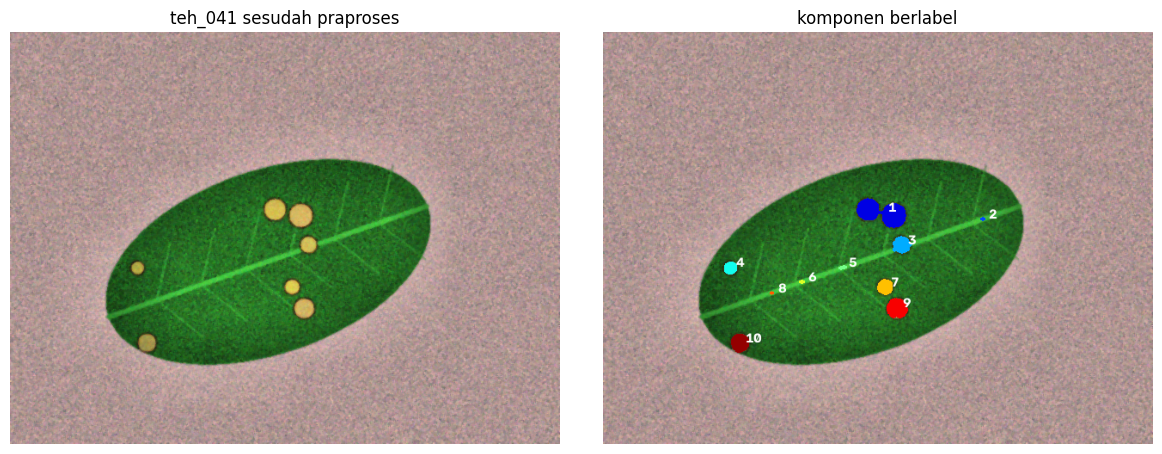

In [11]:
MM_PER_PX = 0.4375      # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))

**Tabel 10.** Ukuran setiap bercak pada teh_041 (disalin dari keluaran Kode 4.1)

| Label | Luas (px) | Luas (mm²) | Keliling (px) | Kebulatan | Rasio aspek | Pusat (x, y) |
|---|---|---|---|---|---|---|
| 1 | 1198 | 229,30 | 183,1 | 0,45 | 1,99 | (324, 210) |
| 2 | 22 | 4,21 | 15,7 | 1,13 | 1,25 | (441, 218) |
| 3 | 342 | 65,46 | 72,8 | 0,81 | 1,14 | (347, 248) |
| 4 | 190 | 36,37 | 48,4 | 1,02 | 1,00 | (147, 274) |
| 5 | 41 | 7,85 | 24,5 | 0,86 | 2,17 | (278, 274) |
| 6 | 27 | 5,17 | 17,7 | 1,09 | 1,50 | (231, 291) |
| 7 | 267 | 51,11 | 58,9 | 0,97 | 1,06 | (327, 297) |
| 8 | 17 | 3,25 | 13,7 | 1,15 | 1,25 | (196, 304) |
| 9 | 463 | 88,62 | 82,4 | 0,86 | 1,04 | (341, 321) |
| 10 | 370 | 70,82 | 69,7 | 0,96 | 1,05 | (158, 362) |

Konektivitas 4 dan 8 sama-sama 10 komponen. Dengan aturan luas ≥ 20, kebulatan ≥ 0,5, dan rasio ≤ 1,8, label 1 (kebulatan 0,45; rasio 1,99), label 5 (rasio 2,17), dan label 8 (luas 17) tersaring, tersisa 7 komponen, sama dengan jumlah bercak acuan (7).


### Langkah 4.3 Saring bercak palsu  `# DARI PETUNJUK` (Kode 4.2)

In [12]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.20    1.20   1.40
luas + kebulatan + rasio   0.60    0.45   0.85
luas >= 20                 1.95    2.05   2.30
tanpa saring               2.75    3.20   3.10
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan            10
luas + kebulatan + rasio     9
luas >= 20                  11
tanpa saring                12
Name: palsu, dtype: int64


**Tabel 11.** Hasil aturan penyaringan (disalin dari keluaran Kode 4.2)

| Aturan | Galat jumlah berat | Galat jumlah ringan | Galat jumlah sehat | Daun sehat dengan bercak palsu |
|---|---|---|---|---|
| tanpa saring | 2,75 | 3,20 | 3,10 | 12 |
| luas ≥ 20 | 1,95 | 2,05 | 2,30 | 11 |
| luas + kebulatan | 1,20 | 1,20 | 1,40 | 10 |
| luas + kebulatan + rasio | 0,60 | 0,45 | 0,85 | 9 |

(Daun sehat berjumlah 20; masih ada 9 yang memiliki bercak palsu walau sudah disaring penuh.)


### Langkah 4.4 KERJAKAN SENDIRI: dasar ambang penyaringan
Untuk setiap komponen hasil pembersihan pada 60 citra, tandai **benar** bila > separuh pikselnya berada di `mask_bercak` acuan, **palsu** bila tidak. Buat diagram sebar kebulatan (y) terhadap rasio aspek (x), warna berbeda untuk benar dan palsu. Pakai diagram ini untuk menjustifikasi `luas_min`, `bulat_min`, `rasio_maks`.

Petunjuk: dalam loop 60 citra, panggil `ukur_komponen(bersih)` yang mengembalikan `(tabel, lbl)`; untuk tiap label hitung `(mb[lbl == i] > 0).mean() > 0.5`.

komponen benar: 184 | palsu: 182
benar                False    True 
luas_px     count   182.00   184.00
            mean     90.08   293.46
            std     202.85   232.66
            min       1.00    17.00
            25%      17.00   119.75
            50%      28.00   223.50
            75%      61.25   447.75
            max    1599.00  1250.00
kebulatan   count   182.00   184.00
            mean      0.77     0.94
            std       0.40     0.12
            min       0.00     0.45
            25%       0.44     0.92
            50%       0.95     0.96
            75%       1.15     1.00
            max       1.15     1.15
rasio_aspek count   182.00   184.00
            mean      3.84     1.10
            std       6.87     0.18
            min       0.00     1.00
            25%       1.25     1.00
            50%       1.70     1.04
            75%       3.38     1.09
            max      51.16     1.99


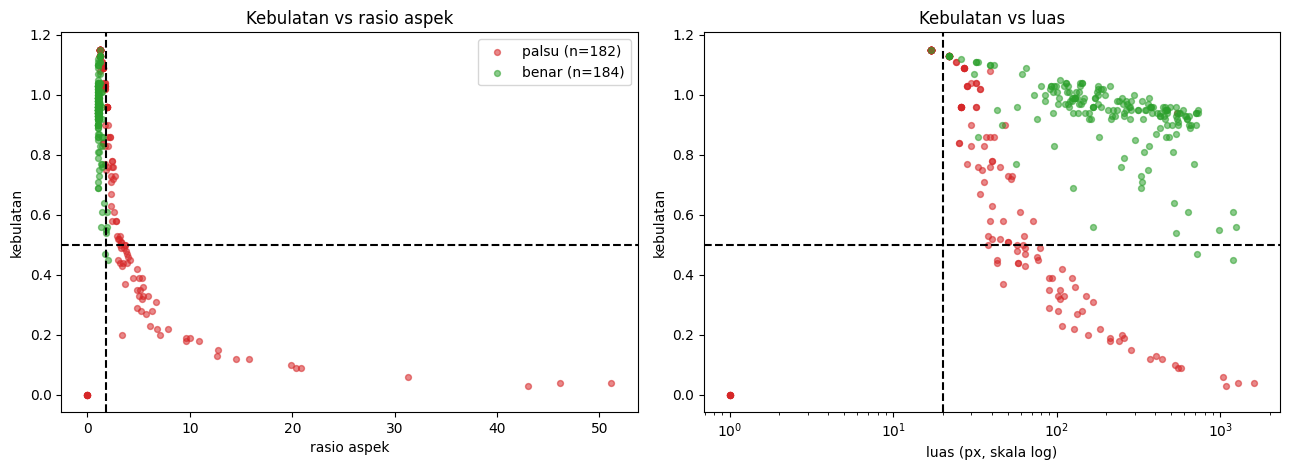

luas >= 20                 benar lolos  99.5% | palsu terbuang  30.8%
luas + kebulatan           benar lolos  98.4% | palsu terbuang  57.1%
luas + kebulatan + rasio   benar lolos  97.3% | palsu terbuang  78.0%


In [13]:
# Langkah 4.4: dasar ambang penyaringan (komponen benar vs palsu, 60 citra)
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    tabel_k, lbl = ukur_komponen(bersih)
    for _, r in tabel_k.iterrows():
        benar = (mb[lbl == int(r.label)] > 0).mean() > 0.5       # > separuh piksel di mask acuan
        baris.append([d.nama_file, d.kelas, r.luas_px, r.kebulatan, r.rasio_aspek, benar])
komp = pd.DataFrame(baris, columns=["nama", "kelas", "luas_px", "kebulatan", "rasio_aspek", "benar"])
print("komponen benar:", int(komp.benar.sum()), "| palsu:", int((~komp.benar).sum()))
print(komp.groupby("benar")[["luas_px", "kebulatan", "rasio_aspek"]].describe().T.round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for nilai, warna, nama_ in [(False, "tab:red", "palsu"), (True, "tab:green", "benar")]:
    s = komp[komp.benar == nilai]
    ax[0].scatter(s.rasio_aspek, s.kebulatan, c=warna, alpha=0.55, s=18, label=f"{nama_} (n={len(s)})")
    ax[1].scatter(s.luas_px, s.kebulatan, c=warna, alpha=0.55, s=18, label=nama_)
ax[0].axvline(1.8, ls="--", c="k"); ax[0].axhline(0.5, ls="--", c="k")
ax[0].set_xlabel("rasio aspek"); ax[0].set_ylabel("kebulatan"); ax[0].legend(); ax[0].set_title("Kebulatan vs rasio aspek")
ax[1].axvline(20, ls="--", c="k"); ax[1].axhline(0.5, ls="--", c="k"); ax[1].set_xscale("log")
ax[1].set_xlabel("luas (px, skala log)"); ax[1].set_ylabel("kebulatan"); ax[1].set_title("Kebulatan vs luas")
plt.tight_layout(); plt.savefig("../hasil/p6_scatter_komponen.png", dpi=150, bbox_inches="tight"); plt.show()

# seberapa banyak komponen benar yang lolos dan palsu yang terbuang untuk setiap aturan
for nm, (a, b, r) in {"luas >= 20": (20, 0, 99), "luas + kebulatan": (20, 0.5, 99),
                      "luas + kebulatan + rasio": (20, 0.5, 1.8)}.items():
    lolos = (komp.luas_px >= a) & (komp.kebulatan >= b) & (komp.rasio_aspek <= r)
    print(f"{nm:26s} benar lolos {100*lolos[komp.benar].mean():5.1f}% | palsu terbuang {100*(~lolos[~komp.benar]).mean():5.1f}%")

In [14]:
# Pendukung P4.4: luas total bercak teh_041 vs mask acuan, dan penyebab selisihnya
img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
b0 = bercak_awal(pra_, m_daun)
opn = cv2.morphologyEx(b0, cv2.MORPH_OPEN, SE(5))
bersih = cv2.morphologyEx(opn, cv2.MORPH_CLOSE, SE(5))
luas_acuan = int((mb > 0).sum())
for nm, m in [("bercak_awal", b0), ("sesudah opening", opn), ("sesudah opening+closing", bersih)]:
    L = int((m > 0).sum())
    print(f"{nm:25s} luas {L:6d} px | acuan {luas_acuan} px | selisih {100*(L-luas_acuan)/luas_acuan:+.1f}%")
# nilai kanal R: dalam bercak, cincin kecokelatan di tepi bercak, dan daun sekitarnya
cincin = (cv2.dilate(mb, SE(7)) > 0) & (cv2.erode(mb, SE(7)) == 0) & (mb == 0) | ((mb > 0) & (cv2.erode(mb, SE(7)) == 0))
print("R rata-rata: dalam bercak", round(float(pra_[:, :, 2][cv2.erode(mb, SE(7)) > 0].mean()), 1),
      "| cincin tepi", round(float(pra_[:, :, 2][cincin].mean()), 1),
      "| daun", round(float(pra_[:, :, 2][(m_daun > 0) & (cv2.dilate(mb, SE(15)) == 0)].mean()), 1))

bercak_awal               luas   3898 px | acuan 3237 px | selisih +20.4%
sesudah opening           luas   2921 px | acuan 3237 px | selisih -9.8%
sesudah opening+closing   luas   2937 px | acuan 3237 px | selisih -9.3%
R rata-rata: dalam bercak 203.2 | cincin tepi 74.5 | daun 37.7


### Pertanyaan Analisis Bagian 4
- **P4.1** Bandingkan kebulatan bercak dan garis (lembar hitung). Mengapa kebulatan bercak 3x3 tidak sama dengan 1? Mengapa pada komponen sangat kecil kebulatan OpenCV bisa > 1?
- **P4.2** Asumsi di balik 1 piksel = 0,4375 mm. Apa yang terjadi pada luas mm² bila jarak foto 30 cm, dan bagaimana SIMUTEH mengatasinya pada foto nyata?
- **P4.3** Dari Tabel 11 dan diagram sebar, aturan mana paling efektif membuang bercak palsu? Risiko aturan rasio aspek pada bercak memanjang atau dua bercak menyatu?
- **P4.4** Bandingkan luas total bercak hasil Anda pada teh_041 dengan mask acuan: lebih besar/kecil, selisih berapa persen, dan penyebabnya (petunjuk: cincin kecokelatan di tepi bercak pada kanal R, penapis median, closing).

### Draf jawaban Bagian 4 (rujuk keluaran Anda)

**P4.1.** Bercak 3×3: kebulatan 4π·9/12² = 0,785; garis 1×6: 4π·6/14² = 0,385. Bercak 3×3 tidak mencapai 1 karena bentuknya persegi (keliling sisi piksel 12), dan nilai 1 hanya dicapai lingkaran sempurna; persegi maksimum π/4 = 0,785. Garis jauh lebih rendah karena kelilingnya besar dibanding luasnya. Pada komponen sangat kecil kebulatan OpenCV bisa > 1 karena `arcLength` mengukur kontur melalui pusat piksel, yang lebih pendek daripada keliling sisi piksel, sedangkan luas dihitung dengan seluruh piksel. Pada Tabel 10: label 8 (17 px) kebulatan 1,15; label 2 (22 px) 1,13; label 6 (27 px) 1,09.

**P4.2.** Asumsi: jarak kamera ke daun tetap 200 mm; kamera tegak lurus ke daun yang datar; lebar bidang kerja 640 px setara 280 mm (640 × 0,4375); tanpa distorsi lensa; piksel persegi. Bila jarak 30 cm, skala mm/piksel naik 1,5 kali (0,656 mm/px), sehingga luas satu piksel naik 1,5² = 2,25 kali. Jika SIMUTEH tetap memakai 0,4375, luas mm² yang dilaporkan hanya sekitar 44% dari luas sebenarnya (terlalu kecil 2,25 kali). Persen bercak tidak terpengaruh karena rasio luas bercak terhadap luas daun sama-sama berskala. Pada foto nyata, SIMUTEH perlu skala per foto, misalnya objek referensi berukuran diketahui (koin, penggaris, atau marker) di dalam foto, atau jarak baku yang dijaga dengan alat bantu.

**P4.3.** Dari Tabel 11 aturan **luas + kebulatan + rasio** paling efektif (galat 0,60/0,45/0,85; sehat berbercak palsu 12 → 9). Diagram sebar (Langkah 4.4) menunjukkan seberapa baik ambang 20, 0,5, dan 1,8 memisahkan komponen benar dari palsu; kutip persentase "benar lolos" dan "palsu terbuang" dari keluaran Anda. Risiko aturan rasio aspek: bercak nyata yang memanjang (misalnya mengikuti tulang daun) ikut dibuang, dan dua bercak yang menyatu membentuk objek memanjang yang ditolak sekaligus sehingga dua bercak hilang. Bercak sintetis berbentuk lingkaran tidak menunjukkan risiko ini (lihat P5.5). Sembilan daun sehat yang masih berbercak palsu menunjukkan penyaringan bentuk saja belum cukup.

**P4.4.** Isi dari keluaran sel pendukung P4.4: tulis apakah luas hasil lebih besar atau lebih kecil dari acuan dan selisihnya (persen). Faktor yang perlu dijelaskan: (1) cincin kecokelatan di tepi bercak memiliki nilai R lebih rendah daripada inti bercak sehingga ambang median + k × MAD hanya menangkap inti dan tepi bercak terpotong (luas hasil cenderung lebih kecil); (2) penapis median pada praproses menumpulkan tepi bercak kecil; (3) opening mengikis tepi bercak dan closing mengembalikan sebagian, jadi bandingkan luas "sesudah opening" dan "sesudah opening+closing" pada keluaran. Putuskan arah selisih berdasarkan angka Anda sendiri.


## Bagian 5. Integrasi: Modul `src/bercak.py`

### Langkah 5.1 KERJAKAN SENDIRI
Lengkapi tujuh TODO di `../src/bercak.py` (sudah disalin kerangkanya) berdasarkan Kode 3.2, 4.1, dan 4.2. Pemetaan:
- TODO 1-2 `bersihkan` -> opening lalu closing (Kode 3.2/4.2)
- TODO 3-5 `ukur_dan_saring` -> `connectedComponentsWithStats` + ukuran + penyaringan (Kode 4.1/4.2)
- TODO 6-7 `analisis_daun` -> persen bercak dan kelas ("Sehat", "Bercak Ringan", "Bercak Berat")

Nama kelas harus persis seperti di Kode 5.2 (`Sehat`, `Bercak Ringan`, `Bercak Berat`).

In [15]:
%%writefile ../src/bercak.py
"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""
import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,              # kanal terpilih (2 = R)
    "k": 4.0,                # ambang median + k x MAD
    "se_bentuk": "elips",    # "elips", "persegi", "silang"
    "se_open": 5,            # ukuran SE opening (0 = tidak dipakai)
    "se_close": 5,           # ukuran SE closing (0 = tidak dipakai)
    "luas_min": 20,          # piksel
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,     # persen bercak minimum kelas Ringan
    "batas_berat": 2.0,      # persen bercak minimum kelas Berat
    "mm_per_px": 0.4375,
}

_BENTUK = {"elips": cv2.MORPH_ELLIPSE, "persegi": cv2.MORPH_RECT, "silang": cv2.MORPH_CROSS}


def _se(p, uk):
    return cv2.getStructuringElement(_BENTUK[p["se_bentuk"]], (uk, uk))


def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    m = biner
    # TODO 1: opening bila se_open > 0 (membuang titik derau dan tepi/tulang daun yang tipis)
    if p["se_open"] > 0:
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, _se(p, p["se_open"]))
    # TODO 2: closing bila se_close > 0 (menutup lubang kecil di dalam bercak)
    if p["se_close"] > 0:
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, _se(p, p["se_close"]))
    return m


def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    keluar, daftar = np.zeros_like(biner), []
    # TODO 3: label komponen terhubung (konektivitas 8)
    n, lbl, st, cen = cv2.connectedComponentsWithStats((biner > 0).astype(np.uint8), connectivity=8)
    mm2 = p["mm_per_px"] ** 2
    for i in range(1, n):
        # TODO 4: ukur luas, keliling, kebulatan, dan rasio aspek
        luas = int(st[i, cv2.CC_STAT_AREA])
        if luas < p["luas_min"]:                 # penyaringan luas lebih dulu (murah)
            continue
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * luas / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        # TODO 5: simpan hanya komponen yang lolos luas_min, bulat_min, dan rasio_maks
        if kebulatan >= p["bulat_min"] and rasio <= p["rasio_maks"]:
            keluar[lbl == i] = 255
            daftar.append({"label": i, "luas_px": luas, "luas_mm2": round(luas * mm2, 2),
                           "keliling_px": round(float(keliling), 1), "kebulatan": round(float(kebulatan), 2),
                           "rasio_aspek": round(float(rasio), 2),
                           "cx": int(cen[i][0]), "cy": int(cen[i][1])})
    return keluar, daftar


def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""
    p = {**PARAM_BERCAK, **(p or {})}
    m_daun = mask_daun_awal(img_praproses)
    biner = bercak_awal(img_praproses, m_daun, kanal=p["kanal"], k=p["k"])
    m_bercak, daftar = ukur_dan_saring(bersihkan(biner, p), p)
    # TODO 6: persen bercak = luas bercak / luas daun x 100
    luas_daun = int((m_daun > 0).sum())
    persen = 100.0 * int((m_bercak > 0).sum()) / luas_daun if luas_daun > 0 else 0.0
    # TODO 7: kelas dari batas_ringan dan batas_berat
    if persen >= p["batas_berat"]:
        kelas = "Bercak Berat"
    elif persen >= p["batas_ringan"]:
        kelas = "Bercak Ringan"
    else:
        kelas = "Sehat"
    return {"mask_daun": m_daun, "mask_bercak": m_bercak, "jumlah_bercak": len(daftar),
            "persen_bercak": round(float(persen), 3), "kelas": kelas, "bercak": daftar}


def simpan_param(p, path="../hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)


Overwriting ../src/bercak.py


### Langkah 5.2 Evaluasi menyeluruh (Kode 5.2)

Galat absolut rerata persen bercak: 0.642
Korelasi persen prediksi vs acuan : 0.876
Akurasi kelas : 0.85
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             17              2      1
Bercak Ringan             0             14      6
Sehat                     0              0     20
kondisi
bayangan          0.92
gelap             1.00
kontras_rendah    0.50
normal            1.00
terang            0.83
Name: benar, dtype: float64


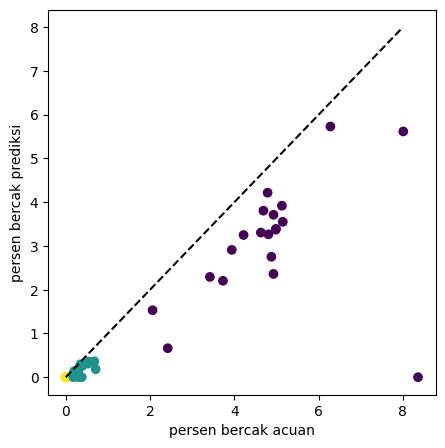

In [16]:
import importlib, bercak
importlib.reload(bercak)

PB = {"k": 6.0}      # pilihan dari Tabel 9 (k = 6, SE elips 5x5 = nilai bawaan); sesuaikan bila temuan Anda berbeda
bercak.simpan_param(PB)
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")
plt.savefig("../hasil/p6_scatter_persen.png", dpi=120, bbox_inches="tight")

In [17]:
# Tambahan (P5.2, P5.3): tuning ringan dengan pembagian data (latih = indeks genap, uji = ganjil)
import itertools
cache = {n: praproses(muat(n)[0], PARAM) for n in label.nama_file}
y = label.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"}).values
persen_acuan = label.persen_bercak.values
latih = (np.arange(len(label)) % 2 == 0); uji_ = ~latih

def kelas_dari(pers, lo, hi):
    return np.where(pers >= hi, "Bercak Berat", np.where(pers >= lo, "Bercak Ringan", "Sehat"))

def cari_batas(pers, y, m):
    terbaik = (-1, None, None)
    for lo in np.arange(0.02, 0.62, 0.02):
        for hi in np.arange(0.6, 5.01, 0.1):
            if hi <= lo: continue
            a = (kelas_dari(pers[m], lo, hi) == y[m]).mean()
            if a > terbaik[0]: terbaik = (a, round(float(lo), 2), round(float(hi), 2))
    return terbaik

baris = []
for k, (bt, uo, uc) in itertools.product([4.0, 5.0, 6.0], [("elips", 5, 5), ("elips", 7, 7), ("persegi", 5, 5)]):
    PBx = {"k": k, "se_bentuk": bt, "se_open": uo, "se_close": uc}
    pers = np.array([bercak.analisis_daun(cache[n], PBx)["persen_bercak"] for n in label.nama_file])
    a_def = (kelas_dari(pers, 0.1, 2.0) == y).mean()
    a_latih, lo, hi = cari_batas(pers, y, latih)
    a_uji = (kelas_dari(pers[uji_], lo, hi) == y[uji_]).mean()
    baris.append([k, bt, uo, uc, round(np.abs(pers - persen_acuan).mean(), 3), round(a_def, 3), lo, hi,
                  round(a_latih, 3), round(a_uji, 3)])
tuning = pd.DataFrame(baris, columns=["k", "bentuk", "open", "close", "galat_persen", "akurasi_batas_bawaan",
                                      "batas_ringan", "batas_berat", "akurasi_latih", "akurasi_uji"])
print(tuning.sort_values("akurasi_uji", ascending=False).to_string(index=False))
tuning.to_csv("../hasil/p6_tuning_bercak.csv", index=False)

  k  bentuk  open  close  galat_persen  akurasi_batas_bawaan  batas_ringan  batas_berat  akurasi_latih  akurasi_uji
6.0   elips     5      5         0.642                 0.850          0.02          0.6          0.900        0.933
5.0 persegi     5      5         0.629                 0.817          0.02          0.6          0.867        0.933
6.0 persegi     5      5         0.669                 0.800          0.02          0.6          0.867        0.933
4.0   elips     5      5         0.529                 0.833          0.06          0.6          0.900        0.900
5.0   elips     7      7         0.668                 0.833          0.02          0.6          0.833        0.900
5.0   elips     5      5         0.603                 0.850          0.04          0.6          0.867        0.900
4.0   elips     7      7         0.582                 0.817          0.02          0.6          0.900        0.867
6.0   elips     7      7         0.721                 0.800          0.

**Tabel 12** - salin: galat absolut rerata persen bercak, korelasi, akurasi kelas, jumlah daun sehat dinilai berbercak, jumlah berbercak dinilai sehat, kondisi cahaya dengan akurasi terendah.

### Langkah 5.3 KERJAKAN SENDIRI: analisis kesalahan
Tampilkan setiap citra yang salah kelas (`ev[ev.kelas_prediksi != ev.kelas_acuan]`): citra hasil praproses, mask bercak hasil (`h["mask_bercak"]`), dan mask bercak acuan berdampingan (pakai `tampil`). Tulis penyebab kesalahan setiap citra.

Daun sehat dinilai berbercak : 0
Daun berbercak dinilai sehat : 7
Kondisi dengan akurasi terendah: kontras_rendah 0.5

9 citra salah kelas
       nama        kondisi  persen_acuan  persen_prediksi  jumlah_acuan  jumlah_prediksi   kelas_acuan kelas_prediksi
teh_023.png         terang          0.25            0.041             2                1 Bercak Ringan          Sehat
teh_024.png kontras_rendah          0.36            0.000             2                0 Bercak Ringan          Sehat
teh_029.png kontras_rendah          0.30            0.000             1                0 Bercak Ringan          Sehat
teh_033.png         terang          0.24            0.044             2                1 Bercak Ringan          Sehat
teh_034.png kontras_rendah          0.18            0.000             1                0 Bercak Ringan          Sehat
teh_039.png kontras_rendah          0.38            0.000             2                0 Bercak Ringan          Sehat
teh_049.png kontras_rendah         

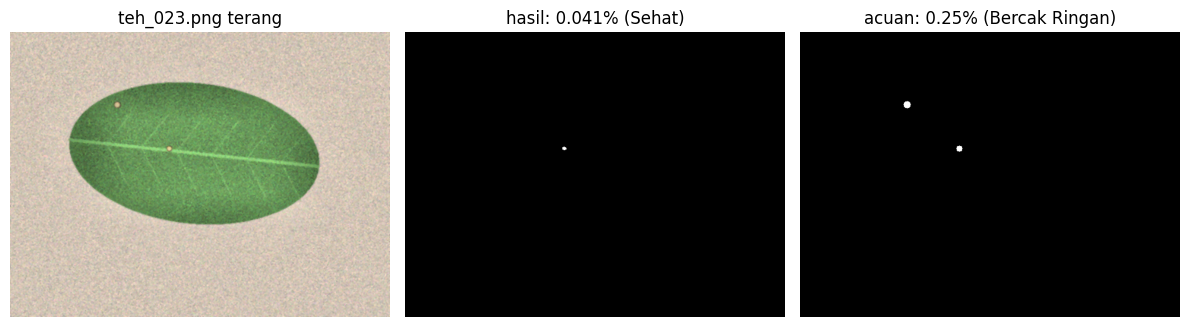

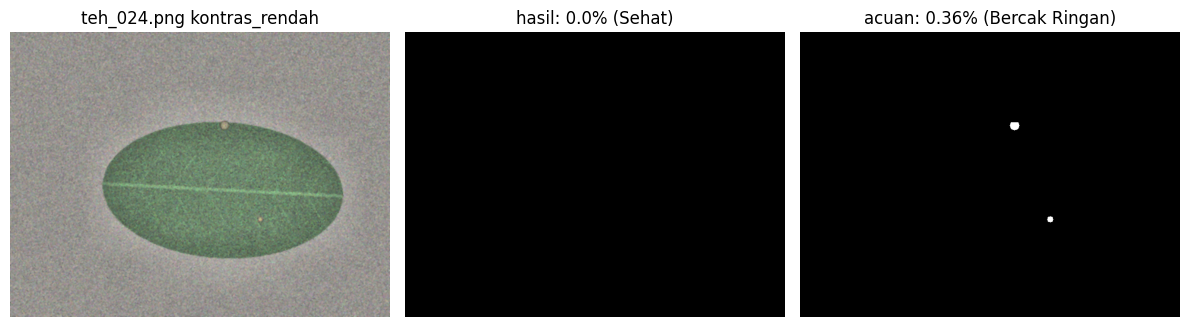

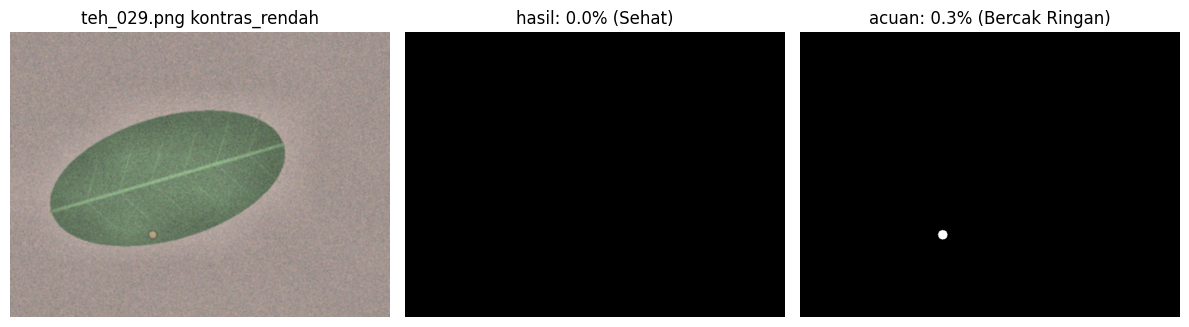

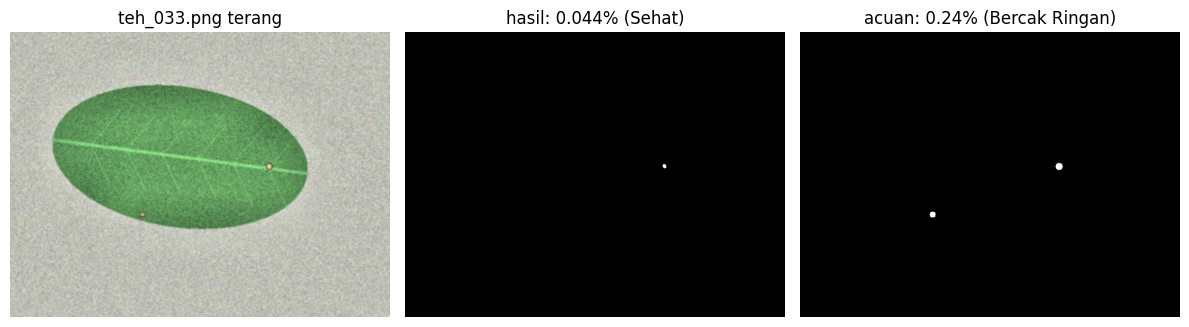

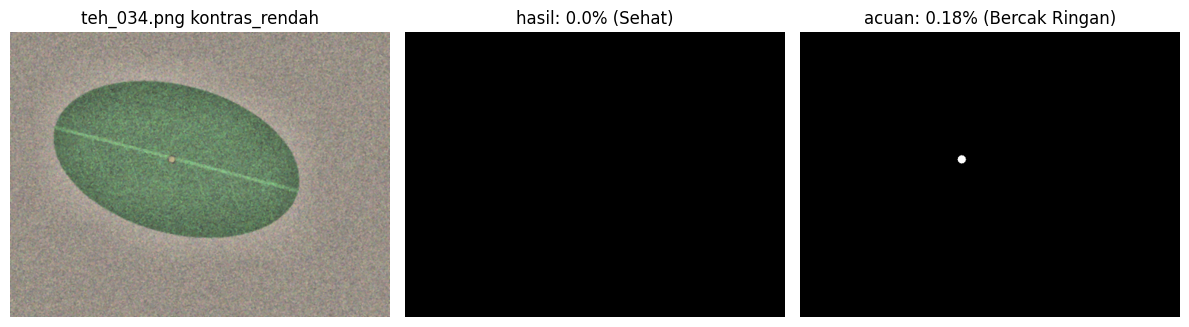

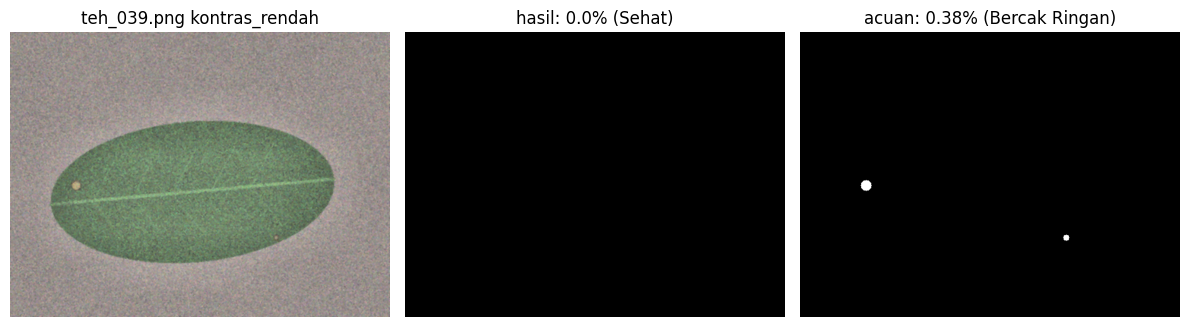

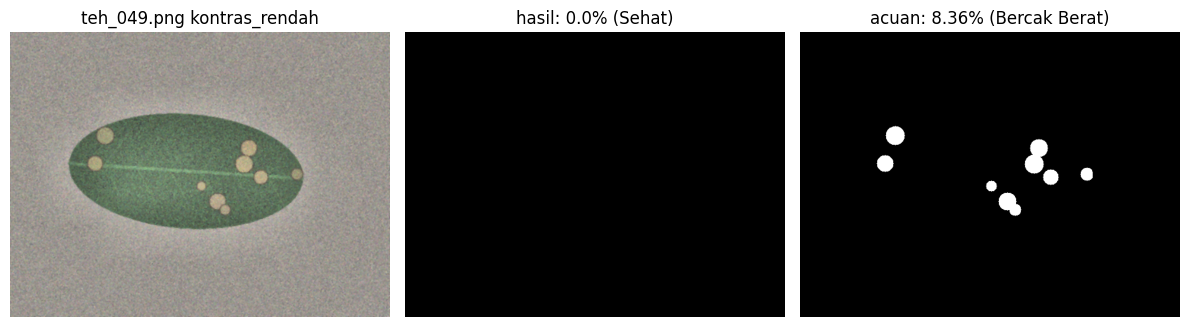

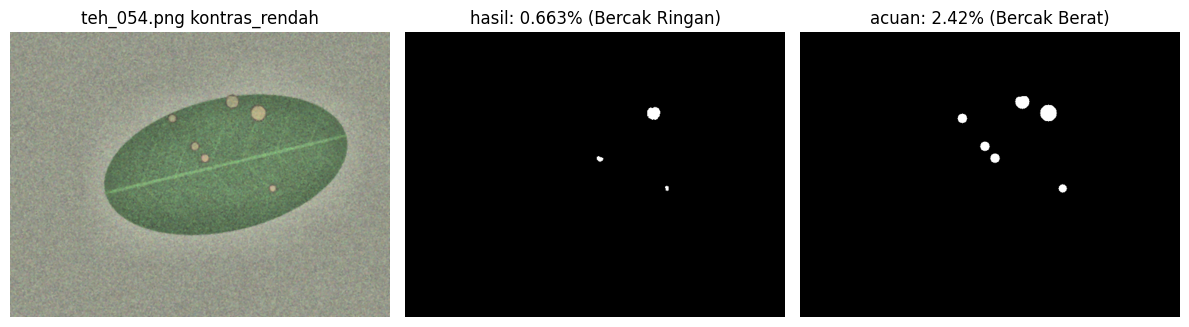

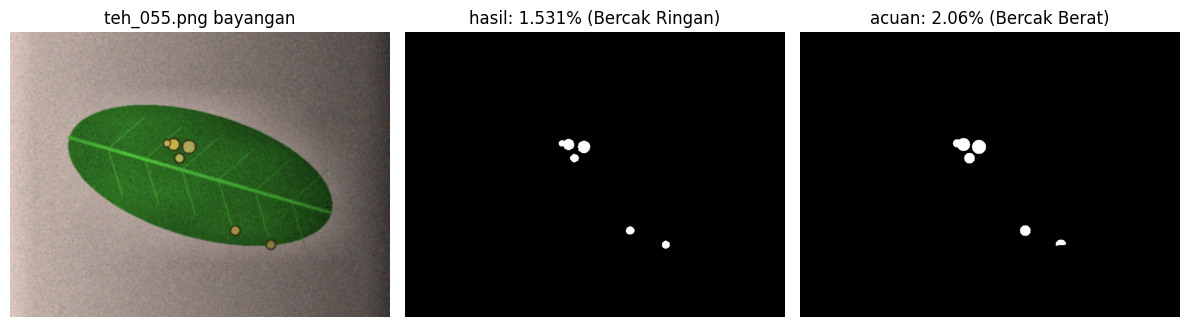

In [18]:
# Langkah 5.3: analisis kesalahan
PB_ = PB
print("Daun sehat dinilai berbercak :", int(((ev.kelas_acuan == "Sehat") & (ev.kelas_prediksi != "Sehat")).sum()))
print("Daun berbercak dinilai sehat :", int(((ev.kelas_acuan != "Sehat") & (ev.kelas_prediksi == "Sehat")).sum()))
acc_kond = ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean()
print("Kondisi dengan akurasi terendah:", acc_kond.idxmin(), round(float(acc_kond.min()), 2))

salah = ev[ev.kelas_prediksi != ev.kelas_acuan].copy()
print(f"\n{len(salah)} citra salah kelas")
print(salah[["nama", "kondisi", "persen_acuan", "persen_prediksi", "jumlah_acuan",
             "jumlah_prediksi", "kelas_acuan", "kelas_prediksi"]].to_string(index=False))

for _, r in salah.head(12).iterrows():          # tampilkan maks. 12 citra; ubah head(12) bila perlu
    img, md, mb = muat(r.nama)
    pra_ = praproses(img, PARAM)
    h = bercak.analisis_daun(pra_, PB_)
    tampil([pra_, h["mask_bercak"], mb],
           [f"{r.nama} {r.kondisi}", f"hasil: {r.persen_prediksi}% ({r.kelas_prediksi})",
            f"acuan: {r.persen_acuan}% ({r.kelas_acuan})"], ukuran=(12, 3.6))
    plt.show()
# Tulis penyebab setiap citra di sel markdown berikutnya (praproses, bercak_awal, atau penyaringan?)

### Langkah 5.4 Tabel 13: justifikasi parameter (isi sendiri)
| Parameter | Nilai final | Alasan dan bukti (rujuk tabel/gambar) | Risiko bila salah atur |
|---|---|---|---|
| kanal dan k | R (2), k = 6 | Kanal R memberi F1 tepi tertinggi (Tabel 6) dan kontras bercak terbesar; pada Tabel 9, k = 6 memberi galat jumlah paling kecil (elips 5: 0,55/0,55/0,05) | k terlalu kecil: derau dan tulang daun masuk sebagai bercak; k terlalu besar: bercak ringan yang redup hilang |
| se_bentuk, se_open, se_close | elips, 5, 5 | Tabel 9 (k = 6) dan keluaran Kode 3.2: opening membuang titik derau, closing menutup lubang; elips 3 identik dengan silang 3 (P3.4) | SE terlalu besar: bercak kecil terhapus; terlalu kecil: derau/tulang daun tersisa; closing terlalu besar: bercak dan potongan tulang daun menyatu |
| luas_min | 20 | Tabel 11: galat turun saat luas ≥ 20 dipakai; diagram sebar luas (Langkah 4.4) | Terlalu besar: bercak ringan kecil hilang; terlalu kecil: butir derau dihitung bercak |
| bulat_min dan rasio_maks | 0,5 dan 1,8 | Tabel 11 (aturan luas + kebulatan + rasio terbaik) dan diagram sebar benar vs palsu | Terlalu ketat: bercak nyata tidak beraturan atau menyatu ditolak; terlalu longgar: potongan tulang daun lolos |
| batas_ringan dan batas_berat | 0,1 dan 2,0 (bawaan; cek `p6_tuning_bercak.csv`) | Batas bawaan diperoleh dari seluruh label.csv sehingga optimistis (P5.2); bandingkan akurasi latih vs uji pada hasil tuning | Terlalu rendah: daun sehat dinilai berbercak; terlalu tinggi: daun berbercak dinilai sehat |

*(Draf: perbarui nilai final bila hasil Kode 5.2 dan tuning Anda menunjukkan kombinasi lain yang lebih baik.)*


### Langkah 5.5 Reprodusibilitas
Jalankan ulang kedua notebook dengan **Restart & Run All**, perbarui `README.md` (ringkasan hasil P5-P6 dan cara memakai `analisis_daun`), lalu:
```
git add .
git commit -m "P6: morfologi, komponen terhubung, dan modul bercak.py"
git tag v0.3-morfologi
git push --tags
```

### Pertanyaan Analisis Bagian 5
- **P5.1** Seberapa tepat SIMUTEH v0.3 mengukur persen bercak dan menebak kelas? Jelaskan tiap kesalahan dan penyebabnya (Langkah 5.3).
- **P5.2** Mengapa menentukan batas 0,1% dan 2,0% dari `label.csv` seluruh dataset membuat akurasi terlalu optimistis? Bagaimana seharusnya (latih/validasi/uji, P11)?
- **P5.3** Kondisi cahaya mana yang menghasilkan kesalahan? Dari praproses, citra biner awal, atau penyaringan? Usulan perbaikan untuk P7.
- **P5.4** Mana lebih merugikan bagi kelompok tani: sehat dinilai berbercak atau berbercak dinilai sehat? Parameter apa diubah dan konsekuensinya? Bagaimana SIMUTEH menampilkan hasil agar petugas dapat memeriksa (amanah, transparansi)?
- **P5.5** Aturan mana di modul Anda yang mungkin terlalu cocok dengan bercak sintetis berbentuk lingkaran sempurna dan gagal pada foto nyata? Bagaimana mengujinya?

**Tabel 12.** Ringkasan evaluasi `bercak.py` (isi dari keluaran Kode 5.2 dan Langkah 5.3 setelah `bercak.py` terisi)

| Ukuran | Nilai | Catatan |
|---|---|---|
| Galat absolut rerata persen bercak | (isi) | |
| Korelasi persen prediksi dan acuan | (isi) | |
| Akurasi kelas | (isi) | |
| Jumlah daun sehat yang dinilai berbercak | (isi) | dari sel Langkah 5.3 |
| Jumlah daun berbercak yang dinilai sehat | (isi) | dari sel Langkah 5.3 |
| Kondisi cahaya dengan akurasi terendah | (isi) | dari sel Langkah 5.3 |

> Keluaran Kode 5.2 yang ada di notebook Anda sekarang (galat 1,728, akurasi 0,333, semua "Sehat") berasal dari kerangka `bercak.py` yang belum diisi. Jalankan ulang setelah sel `%%writefile` pada Langkah 5.1, lalu isi tabel ini.

### Draf jawaban Bagian 5

**P5.1.** Isi dengan angka Tabel 12 dan analisis Langkah 5.3: sebutkan persen galat, akurasi kelas, serta penyebab setiap citra salah (praproses, bercak awal, atau penyaringan). Dugaan yang perlu dibuktikan dengan data Anda: pada kontras rendah mask daun awal dapat gagal (lihat P3.5), sehingga persen bercak ikut salah.

**P5.2.** Batas 0,1% dan 2,0% dipilih dengan melihat label.csv seluruh dataset, jadi batas itu sudah "mengintip" data yang kemudian dipakai untuk menilai akurasi (kebocoran data). Akibatnya akurasi terlalu optimistis dan belum tentu berlaku pada citra baru. Seharusnya data dibagi menjadi latih, validasi, dan uji (P11): batas dan parameter dipilih pada data latih/validasi, lalu akurasi dilaporkan hanya pada data uji yang tidak pernah dipakai untuk memilih. Sel tuning menunjukkan perbandingan akurasi latih dan uji.

**P5.3.** Isi dari kolom akurasi per kondisi (Langkah 5.3). Telusuri sumbernya: bila IoU mask daun awal rendah pada suatu kondisi (sel pendukung P3.5), penyebabnya mask daun awal (praproses/segmentasi daun); bila `bercak_awal` memuat banyak derau, penyebabnya ambang median + k × MAD; bila bercak palsu lolos, penyebabnya penyaringan. Usulan uji pada P7: Otsu adaptif atau klaster untuk mask daun, ambang adaptif untuk bercak, dan watershed untuk bercak yang menyatu.

**P5.4.** Pilih satu jenis kesalahan dan justifikasi. Argumen untuk "berbercak dinilai sehat" sebagai yang lebih merugikan: daun bermutu rendah lolos ke pembeli dan penyakit tidak ditangani sehingga menyebar. Argumen untuk "sehat dinilai berbercak": daun layak dijual diturunkan kelasnya sehingga petani rugi. Untuk menekan kesalahan jenis pertama, turunkan `batas_ringan`, `luas_min`, dan `bulat_min`; konsekuensinya lebih banyak daun sehat dinilai berbercak. SIMUTEH sebaiknya menampilkan citra dengan overlay mask bercak, jumlah, persen, dan kelas, disertai tanda "perlu diperiksa" untuk persen dekat batas kelas, serta memberi petugas kewenangan mengubah keputusan akhir (amanah dan transparansi).

**P5.5.** Aturan yang paling terlalu cocok dengan data sintetis: `bulat_min` (0,5) dan `rasio_maks` (1,8), karena bercak sintetis berupa lingkaran sempurna (kebulatan tinggi dan rasio ≈ 1), serta SE elips yang cocok dengan bercak bulat. Pada foto nyata bercak tidak beraturan, memanjang, atau menyatu sehingga bercak asli dapat ditolak. Pengujian: buat bercak non-lingkaran (elips memanjang, bentuk acak, dua bercak bersentuhan) pada citra uji atau kumpulkan foto nyata dengan anotasi manual, lalu ukur galat jumlah, galat persen bercak, dan akurasi kelas sebelum dan sesudah melonggarkan `bulat_min` dan `rasio_maks`.
